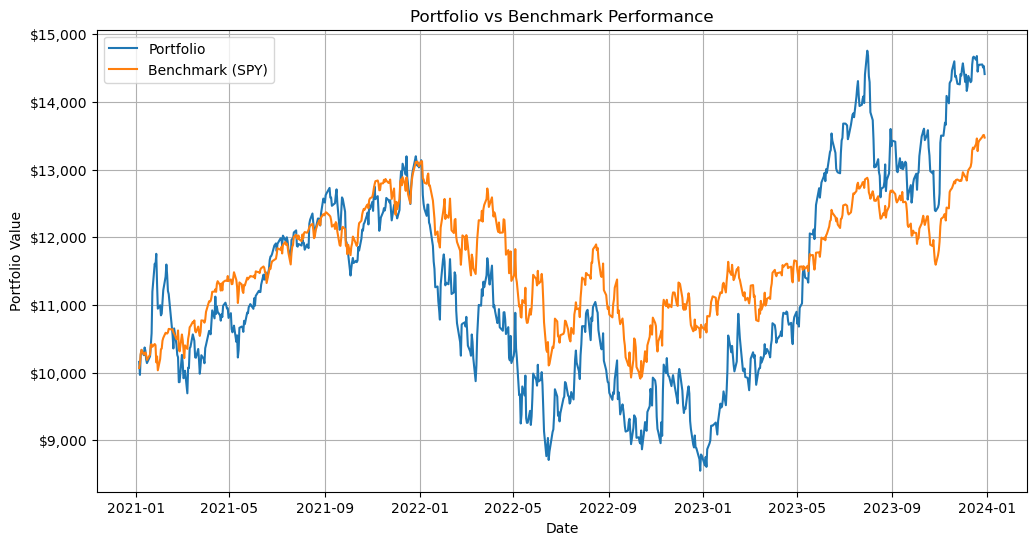

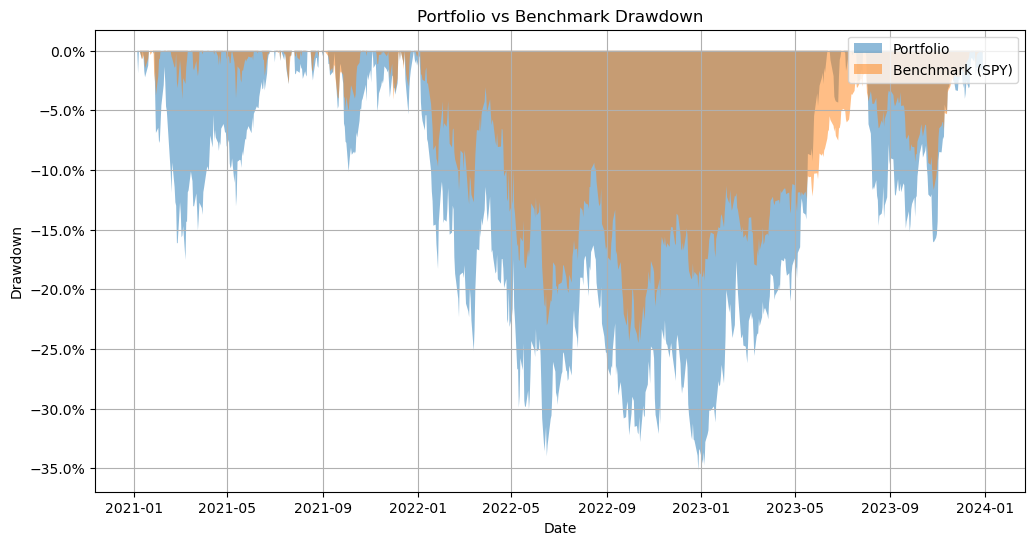

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from results import BacktestResult
from metrics import drawdown_series

def visualize_backtest_result(result: BacktestResult):
    plt.figure(figsize=(12, 6))
    plt.plot(result.portfolio_values, label="Portfolio")
    plt.plot(result.benchmark_values, label=f"Benchmark ({result.benchmark_ticker})")
    plt.title("Portfolio vs Benchmark Performance")
    plt.xlabel("Date")
    plt.ylabel("Portfolio Value")
    plt.gca().yaxis.set_major_formatter('${x:,.0f}')
    plt.legend()
    plt.grid()
    plt.show()

def visualize_drawdown(result: BacktestResult):
    plt.figure(figsize=(12,6))
    portfolio_drawdown = drawdown_series(result.portfolio_values)
    benchmark_drawdown = drawdown_series(result.benchmark_values)
    plt.fill_between(portfolio_drawdown.index, -portfolio_drawdown, alpha=0.4, label="Portfolio")
    plt.fill_between(benchmark_drawdown.index, -benchmark_drawdown, alpha=0.4, label=f"Benchmark ({result.benchmark_ticker})")
    plt.title("Portfolio vs Benchmark Drawdown")
    plt.xlabel("Date")
    plt.ylabel("Drawdown")
    plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
    plt.legend()
    plt.grid()
    plt.show()

if __name__ == "__main__":
    from backtest import backtest
    from visualize import visualize_backtest_result

    result = backtest(["AAPL", "EXPD", "PLTR"], [0.5, 0.3, 0.2], "2021-01-01", "2024-01-01")
    visualize_backtest_result(result)
    visualize_drawdown(result)